# Exploring the dataset and testing one page webscraping

In [27]:
# Action: import libraries
import pandas as pd # loading, cleaning and analysing the data
import numpy as np # numerical operations, if required
import requests # communicate with websites and web APIs using HTTP requests
import re # regular expressions for searching, matching and modifying text patterns
import time # functions for working with time, delays and timestamps

from bs4 import BeautifulSoup # parse and extract information from HTML or XML pages
from collections import Counter # counts how often items appear in an iterable

import matplotlib.pyplot as plt # creates graphs
import seaborn as sns # creates graphs

# visual configuration settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Libraries successfully imported")

Libraries successfully imported


In [136]:
# Loading the dataset and inspecting
df = pd.read_csv("data/original_data.csv")

print("Dataset dimensions", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
df.info()

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False))

Dataset dimensions (1242, 11)

Columns:
['tech_company', 'benefits', 'workplace_resources', 'mh_employer_discussion', 'mh_coworker_discussion', 'medical_coverage', 'mental_health', 'mh_share', 'age', 'gender', 'country']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 1242 entries, 0 to 1241
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   tech_company            1242 non-null   str    
 1   benefits                1242 non-null   str    
 2   workplace_resources     1242 non-null   str    
 3   mh_employer_discussion  1242 non-null   str    
 4   mh_coworker_discussion  1242 non-null   str    
 5   medical_coverage        1242 non-null   str    
 6   mental_health           1242 non-null   str    
 7   mh_share                1242 non-null   int64  
 8   age                     1242 non-null   float64
 9   gender                  1242 non-null   str    
 10  country                 1242 

tech_company              0
benefits                  0
workplace_resources       0
mh_employer_discussion    0
mh_coworker_discussion    0
medical_coverage          0
mental_health             0
mh_share                  0
age                       0
gender                    0
country                   0
dtype: int64

In [116]:
df.head()

,tech_company,benefits,workplace_resources,mh_employer_discussion,mh_coworker_discussion,medical_coverage,mental_health,mh_share,age,gender,country
0,Yes,No,I don't know,No,Yes,Yes,Possibly,5,27.0,Female,United Kingdom
1,Yes,Yes,No,No,Yes,Yes,Possibly,4,31.0,Male,United Kingdom
2,Yes,I don't know,No,Yes,Yes,No,Yes,5,36.0,Male,United States of America
3,Yes,Yes,I don't know,Yes,Yes,Yes,Yes,10,22.0,Male,United States of America
4,Yes,Yes,No,No,Yes,Yes,Yes,8,36.0,Female,United States of America


In [117]:
# Statistical Summary of the Dataset in order to understand the distributions better

print("Numerical variables:")
display(df.describe())

Numerical variables:


,mh_share,age
count,1242.000000,1242.000000
mean,6.572464,35.030598
std,2.701952,8.186624
min,0.000000,19.000000
25%,5.000000,29.000000
50%,7.000000,34.000000
75%,9.000000,40.000000
max,10.000000,66.000000


In [118]:
print("Categorical variables:")
display(df.describe(include=["str"]))

Categorical variables:


,tech_company,benefits,workplace_resources,mh_employer_discussion,mh_coworker_discussion,medical_coverage,mental_health,gender,country
count,1242,1242,1242,1242,1242,1242,1242,1242,1242
unique,2,3,3,2,2,2,4,3,30
top,Yes,Yes,No,No,No,Yes,Yes,Male,United States of America
freq,899,781,465,832,679,1147,553,813,947


In [119]:
# Selecting the columns we are analysing for this project
selected_columns = ["tech_company", "benefits", "workplace_resources", "mh_employer_discussion", "mh_coworker_discussion", "medical_coverage", "mental_health"]

analysis_df = df[selected_columns].copy()

analysis_df

,tech_company,benefits,workplace_resources,mh_employer_discussion,mh_coworker_discussion,medical_coverage,mental_health
0,Yes,No,I don't know,No,Yes,Yes,Possibly
1,Yes,Yes,No,No,Yes,Yes,Possibly
2,Yes,I don't know,No,Yes,Yes,No,Yes
3,Yes,Yes,I don't know,Yes,Yes,Yes,Yes
4,Yes,Yes,No,No,Yes,Yes,Yes
...,...,...,...,...,...,...,...
1237,No,I don't know,No,No,Yes,Yes,Yes
1238,No,Yes,Yes,No,No,Yes,Yes
1239,No,Yes,Yes,Yes,Yes,Yes,Yes
1240,Yes,Yes,Yes,No,No,Yes,No


In [120]:
# Focusing the analysis in workers of tech companies, not just tech workers
analysis_df = analysis_df[
    analysis_df["tech_company"] == "Yes"
].copy()
analysis_df.shape

(899, 7)

In [ ]:
analysis_df.to_csv("/Users/sandragoncalves/Desktop/git-projects/beyond_benefits/employee_benefits_analysis.csv", index=False)

In [132]:
analysis_df["benefits"].unique()

<ArrowStringArray>
['No', 'Yes', 'I don't know']
Length: 3, dtype: str

In [69]:
# Making the category values clearer 
analysis_df["benefits"] = (
    analysis_df["benefits"]
      .str.replace("No", "My employer does not provide benefits", regex=False)
      .str.replace("Yes", "My employer provides benefits", regex=False)
      .str.replace("I don't know", "I don't know if my employer provides benefits", regex=False)
)
analysis_df["benefits"].unique()

<ArrowStringArray>
[        'My employer does not provide benefits',
                 'My employer provides benefits',
 'I don't know if my employer provides benefits']
Length: 3, dtype: str

In [80]:
analysis_df["workplace_resources"].unique()

<ArrowStringArray>
['I don't know', 'No', 'Yes']
Length: 3, dtype: str

In [81]:
analysis_df["workplace_resources"] = (
    analysis_df["workplace_resources"]
      .str.replace("No", "My employer does not provide access resources", regex=False)
      .str.replace("Yes", "My employer provides access resources", regex=False)
      .str.replace("I don't know", "I don't know if my employer provides access resources", regex=False)
)
analysis_df["workplace_resources"].unique()

<ArrowStringArray>
['I don't know if my employer provides access resources',
         'My employer does not provide access resources',
                 'My employer provides access resources']
Length: 3, dtype: str

In [121]:
analysis_df.to_csv("/Users/sandragoncalves/Desktop/git-projects/beyond_benefits/benefits_analysis.csv", index=False)

In [83]:
# Creating a frequency table
pd.crosstab(
    analysis_df["benefits"],
    analysis_df["workplace_resources"],
    margins=True
)

workplace_resources,I don't know if my employer provides access resources,My employer does not provide access resources,My employer provides access resources,All
benefits,,,,
I don't know if my employer provides benefits,99,108,22,229
My employer does not provide benefits,17,84,8,109
My employer provides benefits,139,164,258,561
All,255,356,288,899


In [84]:
# Lets calculate row percentages
pd.crosstab(
    analysis_df["benefits"],
    analysis_df["workplace_resources"],
    normalize="index"
) * 100

workplace_resources,I don't know if my employer provides access resources,My employer does not provide access resources,My employer provides access resources
benefits,,,
I don't know if my employer provides benefits,43.231441,47.161572,9.606987
My employer does not provide benefits,15.596330,77.064220,7.339450
My employer provides benefits,24.777184,29.233512,45.989305


In [38]:
# Setting the graph's colours
colors = sns.color_palette("pastel")[0:5]

In [77]:
# Benefits vs Mental Health
benefits_mh_table = pd.crosstab(
    analysis_df["benefits"], 
    analysis_df["mental_health"],
    normalize="index"
) * 100
display(benefits_mh_table)

mental_health,Don't Know,No,Possibly,Yes
benefits,,,,
I don't know if my employer provides benefits,13.100437,35.371179,25.764192,25.764192
My employer does not provide benefits,7.339450,27.522936,22.935780,42.201835
My employer provides benefits,4.991087,26.381462,17.468806,51.158645


Access to benefits vs Having a mental health condition: among the employees who are sure that teh company provides mental health benefits ("Yes"), about 50.7% report having a mental health condition.
No benefits: For the respondents who reported their company does not provide mental health benefits ("No"), 43.8% declares having a mental health condition, a high rate, as well.
"I don't know": Among the respondents that do not know if the company provides mental health benefits, the larger group is the one that stated not having a mental health condition.
The results suggest that having mental health benefits is significantly related with the group of people that clearly report having mental health conditions.

In [85]:
# Analysis: Workplace resources awareness vs mental health - 
# lets check if the employees that are aware of the available resources in the company ("workplace_resources") are more likely to state they have a mental health situaation ("mental_health")
resources_mh_table = pd.crosstab(
    analysis_df["workplace_resources"],
    analysis_df["mental_health"],
    normalize="index"
) * 100

display(resources_mh_table)


mental_health,Don't Know,No,Possibly,Yes
workplace_resources,,,,
I don't know if my employer provides access resources,8.235294,34.509804,21.568627,35.686275
My employer does not provide access resources,9.269663,24.157303,22.191011,44.382022
My employer provides access resources,4.166667,29.513889,16.666667,49.652778


Employees that know the resources ("Yes"): Among the workers that know the mental health resources that the company provides, 49,6% report having mental health conditions ("Yes").
Employees that report not having access to mental health resources ("No"): The percentage of employees on this group that also report having a mental health condition is high ("Yes"), 44,4%.
Employees that do not know it there are mental health resources available: In this group ,the percentage of employees that report having a mental health condition ("Yes") is 35,7% and the ones that report not having a mental health condition ("No") is 34,5%.
There is a high percentage of employees reporting having a mental health condition, whether or not they knowing or don't know about the mental health resources provided by their company (49,7% and 44,4%). This suggests that making the workplace mental health resources more visible and easy to access is important.

# Analysis: Employer Discussion of Mental Health vs Mental Health Response
Does the employer's initiative to formally discuss mental health is related with the employees perceptions and responses about their mental health?


In [46]:
discussion_mh_table = pd.crosstab(
    analysis_df["mh_employer_discussion"],
    analysis_df["mental_health"],
    normalize="index"
) * 100
display(discussion_mh_table)

mental_health,Don't Know,No,Possibly,Yes
mh_employer_discussion,,,,
No,9.756098,36.236934,21.777003,32.229965
Yes,3.076923,15.692308,17.538462,63.692308


Among respondents whose employer did not discuss mental health, 35% answered "Yes" to mental_health.
Among respondents whose employer did discuss mental health, 60% answered "Yes".

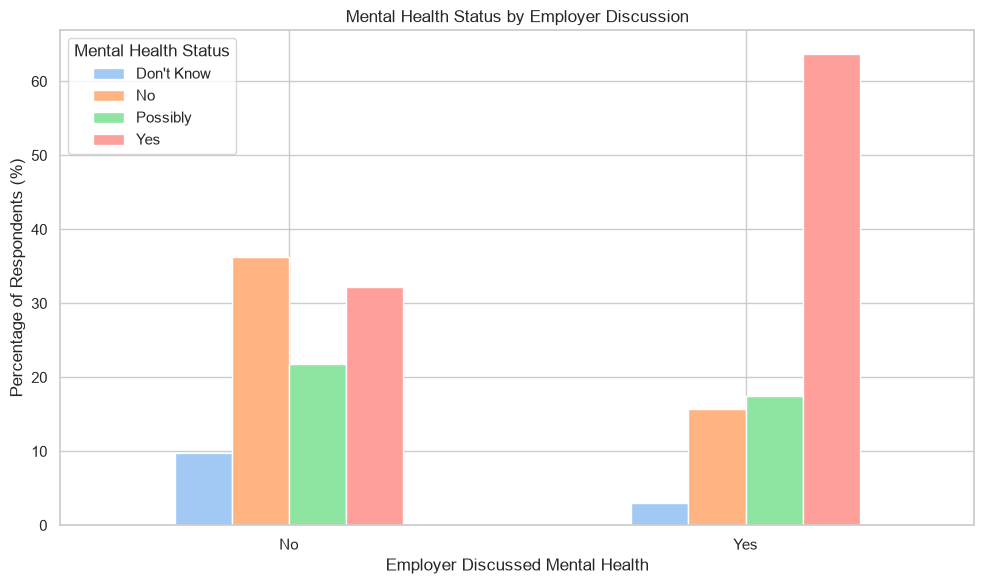

In [48]:
# Grouped bar chart
discussion_mh_table.plot(
    kind="bar",
    stacked=False,
    figsize=(10, 6),
    color=colors
)

plt.title("Mental Health Status by Employer Discussion")
plt.xlabel("Employer Discussed Mental Health")
plt.ylabel("Percentage of Respondents (%)")
plt.legend(title="Mental Health Status")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Analyse H3: Organisational communication
Investigating how organisations communicate the different dimensions of support

In [91]:
# Web scraping GitLab benefits page

url = "https://handbook.gitlab.com/handbook/total-rewards/benefits/"

response = requests.get(url)

print(response.status_code)
print(response.headers.get("Content-Type"))

200
text/html; charset=utf-8


In [92]:
response.headers

{'Cache-Control': 'max-age=600', 'Content-Length': '2328056', 'Content-Type': 'text/html; charset=utf-8', 'Etag': '"cf5c4ee1ce78e3046a4d9beb6095282771ef135248f3386b814eb523e90018a1"', 'Expires': 'Wed, 11 Nov 2026 13:21:28 UTC', 'Last-Modified': 'Wed, 11 Nov 2026 12:02:28 GMT', 'Permissions-Policy': 'interest-cohort=()', 'Vary': 'Origin, Accept-Encoding', 'X-Request-Id': '01M75BR74H9306YH7NKP2ZQYXR', 'Date': 'Wed, 11 Nov 2026 13:11:28 GMT'}

In [93]:
response.raise_for_status()

In [94]:
print(response.text[:1000])

<!doctype html>
<html itemscope itemtype="http://schema.org/WebPage" lang="en" class="no-js" data-theme-init>
  <head>
    <meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1, shrink-to-fit=no">

<meta name="color-scheme" content="light dark">
<meta name="theme-color" media="(prefers-color-scheme: light)" content="#ffffff">
<meta name="theme-color" media="(prefers-color-scheme: dark)"  content="#000000">

<style>
  html { background: Canvas; color: CanvasText; }
  @media (prefers-color-scheme: dark) {
    html { background: #0b0d12; color: #e6e6e6; }
  }
  html[data-theme-init] * { transition: none !important; }
</style>

<script>
  (function() {
    const themeKey = 'td-color-theme';
    const storedTheme = localStorage.getItem(themeKey);
    let theme = storedTheme || (window.matchMedia('(prefers-color-scheme: dark)').matches ? 'dark' : 'light');

    if (theme === 'auto') {
      theme = window.matchMedia('(prefers-color-scheme: dark)').matches 

In [95]:
soup = BeautifulSoup(
    response.text,
    "html.parser"
)

print(type(soup))

<class 'bs4.BeautifulSoup'>


In [96]:
# Inspect what is nested inside what
print(soup.prettify()[:1500])

<!DOCTYPE html>
<html class="no-js" data-theme-init="" itemscope="" itemtype="http://schema.org/WebPage" lang="en">
 <head>
  <meta charset="utf-8"/>
  <meta content="width=device-width, initial-scale=1, shrink-to-fit=no" name="viewport"/>
  <meta content="light dark" name="color-scheme"/>
  <meta content="#ffffff" media="(prefers-color-scheme: light)" name="theme-color"/>
  <meta content="#000000" media="(prefers-color-scheme: dark)" name="theme-color"/>
  <style>
   html { background: Canvas; color: CanvasText; }
  @media (prefers-color-scheme: dark) {
    html { background: #0b0d12; color: #e6e6e6; }
  }
  html[data-theme-init] * { transition: none !important; }
  </style>
  <script>
   (function() {
    const themeKey = 'td-color-theme';
    const storedTheme = localStorage.getItem(themeKey);
    let theme = storedTheme || (window.matchMedia('(prefers-color-scheme: dark)').matches ? 'dark' : 'light');

    if (theme === 'auto') {
      theme = window.matchMedia('(prefers-color-sche

In [97]:
# From website copy outer HTML

html_content = """
<div class="td-content">
  
<h1>Benefits</h1>
  <div class="lead">Overview of GitLab’s Benefit Philosophy and get support with questions</div>
  <header class="article-meta">
    
</header>
  <h2 id="related-benefits-pages">Related Benefits Pages<a class="td-heading-self-link" href="#related-benefits-pages" aria-label="Heading self-link"></a></h2>
<ul>
<li><a href="https://handbook.gitlab.com/handbook/total-rewards/benefits/general-and-entity-benefits/">General &amp; Entity Specific Benefits</a></li>
<li><a href="https://handbook.gitlab.com/handbook/total-rewards/benefits/modern-health/">Modern Health</a></li>
<li><a href="https://handbook.gitlab.com/handbook/total-rewards/benefits/parental-leave-toolkit/">Parental Leave and Return Tool Kit for GitLab Managers and Team Members</a></li>
</ul>
<h2 id="weve-got-you-covered-our-benefits-philosophy">We’ve Got You Covered: Our Benefits Philosophy<a class="td-heading-self-link" href="#weve-got-you-covered-our-benefits-philosophy" aria-label="Heading self-link"></a></h2>
<h3 id="clear-benefits-real-support">Clear Benefits, Real Support<a class="td-heading-self-link" href="#clear-benefits-real-support" aria-label="Heading self-link"></a></h3>
<p>At GitLab, we believe team member Benefits should be simple to understand and there when you need them. From life’s big moments to everyday questions, our comprehensive coverage gives you clarity and confidence so you can focus on your work and life.</p>
<p>Whether you’re planning for the future, starting a family, caring for aging parents, or dealing with unexpected challenges, GitLab’s Benefits are designed to support you at every stage of life—with comprehensive coverage and transparent information when you need it most.</p>
<h3 id="your-support-team-and-resources">Your Support Team and Resources<a class="td-heading-self-link" href="#your-support-team-and-resources" aria-label="Heading self-link"></a></h3>
<p><strong>Need help with your Benefits?</strong> Rest easy knowing you have multiple resources at your fingertips:</p>
<ul>
<li><strong>Start here:</strong> This handbook is your comprehensive guide to understanding GitLab’s Benefit offerings</li>
<li><a href="https://handbook.gitlab.com/handbook/total-rewards/benefits/general-and-entity-benefits/">Company-Wide &amp; Entity/Country Specific Benefits</a> - Complete details on benefits available company-wide and in your location</li>
<li><a href="https://handbook.gitlab.com/handbook/total-rewards/benefits/parental-leave-toolkit/"><strong>Leave Tool Kit for Managers and Team Members</strong></a> - Comprehensive guidance enabling you for life transitions such as parental leave or other types of leave of absence</li>
</ul>
<p><strong>Direct support:</strong> Our Total Rewards team is here to guide you through any questions or life changes. Reach out to us via <a href="https://app.serval.com/new-request">Compass</a>.</p>
<h3 id="our-global-approach">Our Global Approach<a class="td-heading-self-link" href="#our-global-approach" aria-label="Heading self-link"></a></h3>
<h4 id="globally-aligned-locally-relevant">Globally Aligned, Locally Relevant<a class="td-heading-self-link" href="#globally-aligned-locally-relevant" aria-label="Heading self-link"></a></h4>
<p>We recognize that your needs vary depending on where you live and work. That’s why we take a thoughtful, country-specific approach to Benefits rather than a one-size-fits-all solution. We provide competitive Benefit offerings that balance local standards with your needs.</p>
<p>Our country-specific approach considers:</p>
<ul>
<li>Statutory requirements and local regulations</li>
<li>Entity status and headcount considerations</li>
<li>Market practice and standards</li>
<li>Cultural and regional needs</li>
</ul>
<p><strong>What this means for you:</strong></p>
<ul>
<li>Statutory programs are in place in every country where you work</li>
<li>Core medical, life, and pension offerings through statutory or supplementary plans</li>
<li>Country-specific enhancements based on competitive market benchmarking, local needs and regulations</li>
</ul>
<h3 id="our-guiding-principles">Our Guiding Principles<a class="td-heading-self-link" href="#our-guiding-principles" aria-label="Heading self-link"></a></h3>
<h4 id="-continuous-improvement">🔄 Continuous Improvement<a class="td-heading-self-link" href="#-continuous-improvement" aria-label="Heading self-link"></a></h4>
<p>We create new programs with broad reach, high value, and long-term scalability and sustainability. Regular reviews ensure our Benefits evolve with your changing needs, and your feedback directly shapes our offerings.</p>
<h4 id="-inclusive-by-design">🤝 Inclusive by Design<a class="td-heading-self-link" href="#-inclusive-by-design" aria-label="Heading self-link"></a></h4>
<p>Benefits that support all team members, regardless of family structure or life circumstances. We conduct ongoing assessment to ensure our choices reflect our diverse, global team.</p>
<h4 id="-our-credit-values-in-action">💡 Our CREDIT Values in Action<a class="td-heading-self-link" href="#-our-credit-values-in-action" aria-label="Heading self-link"></a></h4>
<p><strong>Collaboration:</strong> We partner with top providers and networks to benchmark against similar companies, fostering understanding across all GitLab entities.</p>
<p><strong>Results:</strong> We make Benefits a meaningful part of your total rewards package, measuring engagement and enrollment to ensure programs truly serve you.</p>
<p><strong>Efficiency:</strong> We streamline processes to make accessing Benefits as simple as possible.</p>
<p><strong>Diversity, Inclusion &amp; Belonging:</strong> We actively ensure our Benefit choices support every team member and regularly assess and improve inclusivity across all programs.</p>
<p><strong>Iteration:</strong> We iterate on improvements based on proven competitive practices and local regulations.</p>
<p><strong>Transparency:</strong> We announce and document our Benefits to keep them updated, share upcoming plans internally before implementing them, and invite discussion and feedback.</p>
<h3 id="how-we-continuously-improve-your-benefits">How We Continuously Improve Your Benefits<a class="td-heading-self-link" href="#how-we-continuously-improve-your-benefits" aria-label="Heading self-link"></a></h3>
<p>Our annual process ensures we’ve got you covered every step of the way:</p>
<h4 id="1-we-listen-to-you">1. We Listen to You<a class="td-heading-self-link" href="#1-we-listen-to-you" aria-label="Heading self-link"></a></h4>
<p>Your voice matters. We carefully review feedback from our Engagement Survey and various team member touchpoints to understand what’s working and where we can better support you.</p>
<h4 id="2-we-research-for-you">2. We Research for You<a class="td-heading-self-link" href="#2-we-research-for-you" aria-label="Heading self-link"></a></h4>
<p>We work with industry experts to benchmark our offerings against other leading tech companies, ensuring you receive competitive total rewards.</p>
<h4 id="3-we-plan-with-you-in-mind">3. We Plan with You in Mind<a class="td-heading-self-link" href="#3-we-plan-with-you-in-mind" aria-label="Heading self-link"></a></h4>
<p>We develop enhancement proposals prioritizing improvements based on market standards, local requirements, headcount limitations, and sustainability.</p>
<h4 id="4-we-explore-every-option">4. We Explore Every Option<a class="td-heading-self-link" href="#4-we-explore-every-option" aria-label="Heading self-link"></a></h4>
<p>We investigate opportunities like multinational pooling to leverage our global presence for better coverage and cost savings that benefit everyone.</p>
<h4 id="5-we-make-informed-decisions">5. We Make Informed Decisions<a class="td-heading-self-link" href="#5-we-make-informed-decisions" aria-label="Heading self-link"></a></h4>
<p>Enhancement proposals are carefully reviewed and approved as part of our annual planning process, ensuring long-term sustainability while meeting your needs.</p>
<h4 id="6-we-keep-you-informed">6. We Keep You Informed<a class="td-heading-self-link" href="#6-we-keep-you-informed" aria-label="Heading self-link"></a></h4>
<ul>
<li><strong>For major changes:</strong> For country specific changes, we create Team Member issues to gather your specific feedback before implementation. We consult and/or inform Works Councils as required.</li>
<li><strong>For smaller changes:</strong> The Total Rewards team may not create an issue for minor adjustments (such as deductible amounts or contribution increases) or legal/required changes for the business.</li>
<li><strong>For all changes:</strong> We track progress and consider your input in our final decisions</li>
<li><strong>Always:</strong> We balance your feedback with market data, budget considerations, and administrative scalability and feasibility</li>
</ul>
<h3 id="7-we-celebrate-improvements-together">7. We Celebrate Improvements Together<a class="td-heading-self-link" href="#7-we-celebrate-improvements-together" aria-label="Heading self-link"></a></h3>
<p>When enhancements are ready, we announce them directly via email, the Loop and/or Slack, and update this handbook immediately so you always have the most current information.</p>
<hr>
<p><em>Remember: Everything at GitLab is always in draft, including our benefits. We’re constantly iterating to better support you. Your feedback and suggestions are always welcome.</em></p>

  <div class="section-index">
  
  
  
  
  
  
  
  <hr class="panel-line">
      
          
          <div class="entry">
              <h5 class="section-summary-header">
                  <a href="https://handbook.gitlab.com/handbook/total-rewards/benefits/general-and-entity-benefits/">General &amp; Entity Specific Benefits &amp; Information</a>
              </h5><div class="section-summary-content">A list of the General &amp; Entity Specific Benefits that GitLab offers as well as other entity-specific information.</div></div>
      
          
          <div class="entry">
              <h5 class="section-summary-header">
                  <a href="https://handbook.gitlab.com/handbook/total-rewards/benefits/parental-leave-toolkit/">Leave of Absence Toolkit for Team Members and Managers</a>
              </h5><div class="section-summary-content">Leave Toolkit for Team Members and Managers</div></div>
      
          
          <div class="entry">
              <h5 class="section-summary-header">
                  <a href="https://handbook.gitlab.com/handbook/total-rewards/benefits/modern-health/">Modern Health</a>
              </h5><div class="section-summary-content">Information on GitLab's Employee Assistance Program.</div></div>
      
  
</div>
<div class="text-muted mt-5 pt-3 border-top">
  Last modified September 11, 2026: <a href="https://gitlab.com/gitlab-com/content-sites/handbook/commit/f511e7a5">compass update (<code>f511e7a5</code>)</a>
</div>





<div class="text-muted pt-3">
<a href="https://gitlab.com/gitlab-com/content-sites/handbook/blob/main/content/handbook/total-rewards/benefits/_index.md" class="td-page-meta--view" target="_blank" rel="noopener">
  <i class="fa fa-file-code fa-fw"></i> View page source
</a>
-
<a href="https://gitlab.com/-/ide/project/gitlab-com/content-sites/handbook/edit/main/-/content/handbook/total-rewards/benefits/_index.md" class="td-page-meta--edit" target="_blank" rel="noopener">
  <i class="fa fa-edit fa-fw"></i> Edit this page
</a>


-
please <a href="https://handbook.gitlab.com/handbook/about/contributing/">contribute</a>.
<a href="https://creativecommons.org/licenses/by-sa/4.0/" target="_blank">
<img alt="Creative Commons License" src="https://i.creativecommons.org/l/by-sa/4.0/80x15.png" style="border-width: 0px;"></a>
</div>

</div>
"""

In [50]:
# Analysing the HTML to get the h2 tags topics
soup_html = BeautifulSoup(html_content, "html.parser")
h2_tags = soup_html.find_all("h2")

print("Main topics found (h2)") 
for idx, h2 in enumerate(h2_tags, start=1):
    title_text = h2.get_text(" ", strip=True)
    title_text = title_text.replace("Heading self-link", "").strip()
    print(f"{idx}. {title_text}")

print("\nRelated statistical context (benefits_mh_table)")
display(benefits_mh_table.round(2))

---Main topics found (h2)---
1. Related Benefits Pages
2. We’ve Got You Covered: Our Benefits Philosophy

---Related statistical context (benefits_mh_table)---


mental_health,Don't Know,No,Possibly,Yes
benefits,,,,
I don't know,13.10,35.37,25.76,25.76
No,7.34,27.52,22.94,42.20
Yes,4.99,26.38,17.47,51.16


Looking into the h2 content, we can identify two main topics: 
1. Related Benefits Pages
2. We've Got You Covered: Our Benefits Philosophy

Topic 1: Communication Channels and Resources

This headline groups links to access specific benefits from the company
Relation with the benefits_mh_table: This website clearly shows specific channels to access the mental health benefits and, looking to the benefits_mh_table, we can find 25,76% of respondents who don't know if their employer provides benefits and state having a mental health condition. 
Even if a company has structures benefits pages, failing to effectively disseminate this information may lead workers elegible to these benefits to miss this information.

Topic 2: Corporate Culture and Processes

This topic presents the company's philosophy that the benefits should be easy to understand, transparent and available when necessary
Relation with the benefits_mh_table: The connection here seems to be strong. When the company have this philosophy active and the benefits are transparent (respondents on the survey that state they have benefits), 51,16% state they have a mental health condition, against 4,99% that don't know if they have a mental health condition. Open communication and a strong welcoming philosophy reduce the communication barriers in the workplace. 

In [57]:
# Analysing the HTML to get the h3 tags topics
h3_tags = soup_html.find_all("h3")

print("Workplace Resources and Philosophy (h3)")
for idx, h3 in enumerate(h3_tags, start=1):
    title_h3 = h3.get_text(" ", strip=True)
    title_h3 = title_h3.replace("Heading self-link", "").strip()
    print(f"{idx}.{title_h3}")

print("\nRelated statistical context (resources_mh_table)")
print(resources_mh_table)

Workplace Resources and Philosophy (h3)
1.Clear Benefits, Real Support
2.Your Support Team and Resources
3.Our Global Approach
4.Our Guiding Principles
5.How We Continuously Improve Your Benefits
6.7. We Celebrate Improvements Together

Related statistical context (resources_mh_table)
mental_health        Don't Know         No   Possibly        Yes
workplace_resources                                             
I don't know           8.235294  34.509804  21.568627  35.686275
No                     9.269663  24.157303  22.191011  44.382022
Yes                    4.166667  29.513889  16.666667  49.652778


The h3 content give us a deeper understanding of how they implement what they communicate:
- Employee benefits and support
- Support teams and resources
- Organisational principles
- Continuous improvement
The employee survey suggests that respondents who report that their employers provide workplace resources also have a relatively high proportion of self-reported mental health conditions.

These findings raise an interesting question: Are workplace mental health resources reaching the employees who may need them most? >> Further investigation

In [98]:
# Structuring the html as a nested Python dictionary
section: {
    "section_title": soup.find("h3").get_text(" ", strip=True),
    "subsection_title": soup.find("h4").get_text(" ", strip=True),
    "paragraphs": [
        paragraph.get_text(" ", strip=True)
        for paragraph in soup.find_all("p")
    ],
    "considerations": [
        item.get_text(" ", strip=True)
        for item in soup.select("ul li")
    ]
}

print(section)       

{'section_title': 'Clear Benefits, Real Support', 'subsection_title': 'Globally Aligned, Locally Relevant', 'paragraphs': ['At GitLab, we believe team member Benefits should be simple to understand and there when you need them. From life’s big moments to everyday questions, our comprehensive coverage gives you clarity and confidence so you can focus on your work and life.', 'Whether you’re planning for the future, starting a family, caring for aging parents, or dealing with unexpected challenges, GitLab’s Benefits are designed to support you at every stage of life—with comprehensive coverage and transparent information when you need it most.', 'Need help with your Benefits? Rest easy knowing you have multiple resources at your fingertips:', 'Direct support: Our Total Rewards team is here to guide you through any questions or life changes. Reach out to us via Compass .', 'We recognize that your needs vary depending on where you live and work. That’s why we take a thoughtful, country-spe

In [102]:
html = response.text
    
def extract_section(html):
    soup = BeautifulSoup(html, "html.parser")

    # Remove navigation/self-link anchors from headings
    for link in soup.select("a.td-heading-self-link"):
        link.decompose()

    h3 = soup.find("h3")
    h4 = soup.find("h4")

    data = {
        "section_title": h3.get_text(" ", strip=True) if h3 else None,
        "subsection_title": h4.get_text(" ", strip=True) if h4 else None,
        "paragraphs": [
            paragraph.get_text(" ", strip=True)
            for paragraph in soup.find_all("p")
        ],
        "considerations": [
            item.get_text(" ", strip=True)
            for item in soup.select("ul li")
        ]
    }

    return data

In [103]:
result = extract_section(html)
print(result)

{'section_title': 'Clear Benefits, Real Support', 'subsection_title': 'Globally Aligned, Locally Relevant', 'paragraphs': ['At GitLab, we believe team member Benefits should be simple to understand and there when you need them. From life’s big moments to everyday questions, our comprehensive coverage gives you clarity and confidence so you can focus on your work and life.', 'Whether you’re planning for the future, starting a family, caring for aging parents, or dealing with unexpected challenges, GitLab’s Benefits are designed to support you at every stage of life—with comprehensive coverage and transparent information when you need it most.', 'Need help with your Benefits? Rest easy knowing you have multiple resources at your fingertips:', 'Direct support: Our Total Rewards team is here to guide you through any questions or life changes. Reach out to us via Compass .', 'We recognize that your needs vary depending on where you live and work. That’s why we take a thoughtful, country-spe

In [104]:
#converting the dictionary into a dataframe
benefits_communications = pd.DataFrame({
    "section_title": result["section_title"],
    "subsection_title": result["subsection_title"],
    "consideration": result["considerations"]
})

print(benefits_communications)

                     section_title                    subsection_title  \
0     Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
1     Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
2     Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
3     Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
4     Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
...                            ...                                 ...   
3604  Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
3605  Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
3606  Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
3607  Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
3608  Clear Benefits, Real Support  Globally Aligned, Locally Relevant   

                                          consideration  
0                                                GitL

In [122]:
# Searching for keywords
keywords = ["health", "support", "benefit", "benefits", "need", "needs", "program", "programs"]

for keyword in keywords:
    count = benefits_communications["consideration"].str.contains(
        keyword,
        case=False,
        na=False
    ).sum()

    print(keyword, count)

health 37
support 172
benefit 32
benefits 31
need 2
needs 2
program 151
programs 41


In [106]:
# Another way of converting the dictionary into 2 dataframes - paragraphs and considerations separate
paragraphs_df = pd.DataFrame({
    "section_title": result["section_title"],
    "subsection_title": result["subsection_title"],
    "paragraph": result["paragraphs"]
})

considerations_df = pd.DataFrame({
    "section_title": result["section_title"],
    "subsection_title": result["subsection_title"],
    "consideration": result["considerations"]
})

print(paragraphs_df)
print(considerations_df)

                   section_title                    subsection_title  \
0   Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
1   Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
2   Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
3   Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
4   Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
5   Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
6   Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
7   Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
8   Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
9   Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
10  Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
11  Clear Benefits, Real Support  Globally Aligned, Locally Relevant   
12  Clear Benefits, Real Support  Globally Aligned, Locally Rele

In [123]:
# Searching for keywords
keywords_paragraph = ["health", "support", "benefit", "benefits", "need", "needs", "program", "programs"]

for keyword in keywords_paragraph:
    count = paragraphs_df["paragraph"].str.contains(
        keyword,
        case=False,
        na=False
    ).sum()

    print(keyword, count)

health 0
support 6
benefit 12
benefits 10
need 6
needs 3
program 3
programs 3


In [107]:
# extracting the content without navigation and other unrelated content
def extract_content(html):
    # Prefer the main article/content area if the page has one
    content = soup.find("main") or soup.find("article") or soup

    # Remove common navigation and non-content elements
    for tag in content.select(
        "header, nav, footer, aside, script, style, "
        ".navigation, .navbar, .menu, .breadcrumb, "
        ".td-heading-self-link"
    ):
        tag.decompose()

    unwanted_text = {
        "GitLab",
        "Handbook",
        "Toggle theme Light Dark Auto",
        "Light",
        "Dark"
    }

    rows = []
    section_title = None
    subsection_title = None

    # Keep headings, paragraphs, and list items in document order
    for element in content.find_all(["h3", "h4", "p", "li"]):

        text = element.get_text(" ", strip=True)

        # Ignore empty or unwanted content
        if not text or text in unwanted_text:
            continue

        if element.name == "h3":
            section_title = text
            subsection_title = None

        elif element.name == "h4":
            subsection_title = text

        elif element.name == "p":
            rows.append({
                "section_title": section_title,
                "subsection_title": subsection_title,
                "content_type": "paragraph",
                "content": text
            })

        elif element.name == "li":
            rows.append({
                "section_title": section_title,
                "subsection_title": subsection_title,
                "content_type": "list_item",
                "content": text
            })

    return pd.DataFrame(rows)

In [108]:
df = extract_content(html)

print(df.head())
print(df.shape)

                  section_title subsection_title content_type  \
0                           NaN              NaN    list_item   
1                           NaN              NaN    list_item   
2                           NaN              NaN    list_item   
3  Clear Benefits, Real Support              NaN    paragraph   
4  Clear Benefits, Real Support              NaN    paragraph   

                                             content  
0                 General & Entity Specific Benefits  
1                                      Modern Health  
2  Parental Leave and Return Tool Kit for GitLab ...  
3  At GitLab, we believe team member Benefits sho...  
4  Whether you’re planning for the future, starti...  
(40, 4)


In [111]:
def extract_section(html, section_id):
    
    # Remove elements that are normally page navigation or technical content
    for tag in soup.select(
        "header, nav, footer, aside, script, style, "
        "button, form, input"
    ):
        tag.decompose()

    # Remove specific unwanted links or labels
    unwanted_text = {
        "GitLab",
        "Handbook",
        "Light",
        "Dark",
        "Auto",
        "Toggle theme Light Dark Auto"
    }

    for tag in soup.find_all(["a", "span", "div"]):
        text = tag.get_text(" ", strip=True)

        if text in unwanted_text:
            tag.decompose()

    # Find the section where extraction should begin
    heading = soup.find(id=section_id)

    if heading is None:
        return pd.DataFrame()

    rows = []
    section_title = heading.get_text(" ", strip=True)
    subsection_title = None

    # Extract only content after the selected heading
    for element in heading.find_all_next(["h3", "h4", "p", "li"]):

        # Stop when the next main section begins
        if element.name == "h3" and element is not heading:
            break

        text = element.get_text(" ", strip=True)

        if not text:
            continue

        if element.name == "h4":
            subsection_title = text

        elif element.name == "p":
            rows.append({
                "section_title": section_title,
                "subsection_title": subsection_title,
                "content_type": "paragraph",
                "content": text
            })

        elif element.name == "li":
            rows.append({
                "section_title": section_title,
                "subsection_title": subsection_title,
                "content_type": "list_item",
                "content": text
            })

    return pd.DataFrame(rows)

In [127]:
df = extract_section(
    html,
    "our-global-approach"
)

print(df)
print(df.shape)

         section_title                    subsection_title content_type  \
0  Our Global Approach  Globally Aligned, Locally Relevant    paragraph   
1  Our Global Approach  Globally Aligned, Locally Relevant    paragraph   
2  Our Global Approach  Globally Aligned, Locally Relevant    list_item   
3  Our Global Approach  Globally Aligned, Locally Relevant    list_item   
4  Our Global Approach  Globally Aligned, Locally Relevant    list_item   
5  Our Global Approach  Globally Aligned, Locally Relevant    list_item   
6  Our Global Approach  Globally Aligned, Locally Relevant    paragraph   
7  Our Global Approach  Globally Aligned, Locally Relevant    list_item   
8  Our Global Approach  Globally Aligned, Locally Relevant    list_item   
9  Our Global Approach  Globally Aligned, Locally Relevant    list_item   

                                             content  
0  We recognize that your needs vary depending on...  
1           Our country-specific approach considers:  
2       S